# Deep Q-Learning: Learning via Experience Replay
## 1. Introduction to the problem & it's relation to Neuroscience
## 2. Environment
## 3. Q Table vs Q network
## 4. Training Algorithm


Temporal Difference Learning methods, like Experience Replay can learn directly from raw experience without a model of the environment's dynamics.
[source](http://incompleteideas.net/book/ebook/node60.html)


Environment
#### Built on Gymnasium & Pytorch
Gymnasium is an API Library for Reinforcemnet Learning and comes prebuilt with game environments.
See the cell below for other packages.

In [2]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
import random
import torch
from torch import nn
import torch.nn.functional as fn

#### Learning Environment: 'Frozen Lake' game

(np.float64(-0.5), np.float64(587.5), np.float64(617.5), np.float64(-0.5))

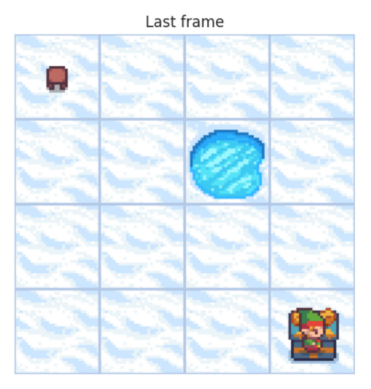

In [7]:
plt.imshow(plt.imread('frozenLake_env.png'))
plt.axis('off')

# Building a Regular Qtable

In [ ]:
# Q-learning algorithm for FrozenLake-v1 using Epsilson Greedy Policy
import pickle

def run(episodes=10000, is_training=True, render=False):
    # Create environment - 8x8 grid Slippery FrozenLakev1
    env = gym.make("FrozenLake-v1", map_name='8x8', is_slippery=True, render_mode= 'human' if render else None)
    # is_slippery=True means there is a chance of the agent 'slipping' on the ice and moving in a different direction than intended. 
    # This addes a level of uncertainty to the environment, making traditional path-finding algorithms uneffective. 
    # Note: If the gaent tries to move off the grid, it will stay in the same position.
    
    if is_training:
        # Create empty Q-table for 64x4 
        q = np.zeros((env.observation_space.n, env.action_space.n))
    else: # load Q-table from file
        f = open("FrozenLake_Qtable.pkl", "rb")
        q = pickle.load(f)
        f.close()

    # Parameters
    alpha_learning_rate = 0.9 # Values closed to 1 mean the agent will learn faster, but it may not converge to the optimal policy. Values close to 0 mean the agent will learn slower, but it may converge to the optimal policy.
    gamma_discount_factor = 0.9 # Values closed to 1 mean the agent will prioritize future rewards, while values close to 0 mean the agent will prioritize immediate rewards.
    # Epislion Greedy Policy Parameters
    epsilon = 1 # Starts at at 1(100% random actions) and overtime we will decrease the randomness using the decay rate.
    epsilon_decay_rate = 0.0001 # At 0.0001, the agent will need 10,00 episodes to reach 0.
    random_generator = np.random.default_rng(12)

    rewards_per_episode = np.zeros(episodes) # Storage for rewards for each episode

    # Start training loop
    for i in range(episodes):
        # Get state: For 8x8 grid, the state is a number between 0 and 63, representing the position in the grid
        state = env.reset()[0]
        terminated = False # True if the episode has ended: the agent has reached the goal or fallen into a hole
        truncated = False # True when action limit is reached

        while(not terminated and not truncated):
        # Epsilon Greedy Policy: Choose a random action with probability epsilon    
            if is_training and random_generator.random() < epsilon: # Get an random Action during traing
                action = env.action_space.sample() # Possible actions: {0: left, 1: down, 2: right, 3: up}
            else: # Lookup Q_Table
                action = np.argmax(q[state,:])
            # Take action, get updated state and rewards and info. Rweard is 1 if the agent has reached the goal, 0 otherwise
            new_state, reward, terminated, truncated, info = env.step(action)

            if is_training: # Calculate Q values for given state and action
                q[state, action] = q[state, action] + alpha_learning_rate * (
                    reward + gamma_discount_factor * np.max(q[new_state,:]) - q[state, action]
                )
            
            # Update state
            state = new_state

        # Decrease epsilon until it reaches 0. This ensures our model will explore and then apply what what it has learned.
        epsilon = max(epsilon-epsilon_decay_rate,0)
            
        # Decrease alpha rate after agent is done learning. This will help stabilize the Q values after the agent is done learning.
        if epsilon == 0:
            alpha_learning_rate = 0.0001

        # Store rewards for each episode
        if reward == 1:
            rewards_per_episode[i] = 1

    # Close the environment
    env.close()
    
    # Calculate total reward for every 100 episodes
    sum_rewards =np.zeros(episodes)
    for i in range(episodes):
        sum_rewards[i] = np.sum(rewards_per_episode[max(0, i-100):(i+1)]) # Calculate the sum of rewards for the last 100 episodes

    # Visualize the results
    plt.plot(sum_rewards) # Plot the rewards
    #plt.title("Rewards per 100 episodes: Q-Learning on Non slip FrozenLake - ADD EPSILON DECAY")
    #plt.title("Rewards per 100 episodes: Q-Learning on Slippery FrozenLake")
    plt.title("Rewards per 100 episodes: Pretrained Q-Learning on Slippery FrozenLake")

    plt.xlabel("Episodes")
    plt.ylabel("Total Reward per 100 epsisodes")
    #plt.savefig("FrozenLake_Q_nonslip.png") # Save the plot
    plt.savefig("FrozenLake_Q_slip.png") # Save the plot
    plt.savefig("FrozenLake_pretrain_Q_slip.png") # Save the plot

    if is_training:# Only save the Q-table while training
        #f = open("FrozenLake_Qtable_nonslip.pkl", "wb")
        f = open("FrozenLake_Qtable.pkl", "wb")
        pickle.dump(q, f)
        f.close()

#run(15000, is_training=True,render=False) # Run the training for 15,000 episodes without rendering
    
#run(10000, is_training=False,render=False) # Run the trained agent for 2 episodes with rendering

In [ ]:
#run(10000, is_training=False,render=False) # Run the trained agent for 2 episodes with rendering
plt.show() # Show the plot

In [ ]:
# Define Feed Forward Model class
class DeepQ_NN(nn.Module):
    def __init__(self, input_layer_size, hidden_layer_size, output_layer_size): # Create function
        super().__init__()
        # Define Layers using Linear Transformations
        self.input_layer = nn.Linear(input_layer_size, hidden_layer_size) # Pass the current state to the Input layer, and pass it to the hidden layer
        self.output_layer = nn.Linear(hidden_layer_size, output_layer_size) # Take hidden layer and pass it to the Output layer

    # Feed forward calculation using ReLU activation function. Takes in training data, x, and passes it through the network.
    def forward(self, x):
        x = fn.relu(self.input_layer(x)) # ReLU activation
        x = self.output_layer(x) # Pass to Output layer    
        return x
    
# Define class for Experience Replay Memory
class ExperienceReplayMemory():
    def __init__(self, max_size): # Initialize the memory with a maximum size
        self.memory = deque([], maxlen=max_size) # Define the memory as a deque with a maximum size

    def append_experience(self, experience): # Append experience to the memory
        self.memory.append(experience)         # experiece is tuple: (state, action, new_state, reward, terminated)

    def sample_experiences(self, batch_size):    
        return random.sample(self.memory, batch_size) # Return sample a batch of experiences from the memory
    
    def __len__(self):
        return len(self.memory) # Return the length of the memory
    
# Define class for Deep Q Learning on FrozenLake
class FrozenLake_DeepQ_Learning():
    # Define Hyperparameters - play with parameters
    alpha_learning_rate = 0.001 # Values closed to 1 mean the agent will learn faster, but it may not converge to the optimal policy. Values close to 0 mean the agent will learn slower, but it may converge to the optimal policy.
    gamma_discount_factor = 0.9 # Values closed to 1 mean the agent will prioritize future rewards, while values close to 0 mean the agent will prioritize immediate rewards.
    network_sync_rate = 10 # Number of actions taken before syncing the target and policy networks. This helps stabilize the training process.
    experience_replay_memory_size = 10000 # Size of the replay memory
    batch_size = 32 # Size of the batch to sample from the replay memory
    
    # NN
    loss_function = nn.MSELoss() # Loss function for the NN - Mean Squared Error Loss
    optimizer = None #torch.optim.Adam # Optimizer for the NN - Adam optimizer 

    # Actions
    action_list = ['L', 'D', 'R', 'U'] # List of actions for the agent: 0,1,2,3

    def train(self, episodes=10000, render=False, is_slippery=False):
        # Create environment - 8x8 grid Slippery FrozenLakev1
        env = gym.make("FrozenLake-v1", map_name='4x4', is_slippery=is_slippery, render_mode= 'human' if render else None)
        num_states = env.observation_space.n # Number of states in the environment - 64
        num_actions = env.action_space.n # Number of actions in the environment - 4

        epsilon = 1 # Starts at at 1(100% random actions) and overtime we will decrease the randomness using the decay rate.
        memory_storage = ExperienceReplayMemory(self.experience_replay_memory_size) # Initialize the experience replay memory
        
        # --------------- Step 1 - Initialize the policy and target network --------------------#
        policy_deepq_nn = DeepQ_NN(input_layer_size=num_states, hidden_layer_size=num_states, output_layer_size=num_actions) # Initialize the policy DeepQ NN
        target_deepq_nn = DeepQ_NN(input_layer_size=num_states, hidden_layer_size=num_states, output_layer_size=num_actions) # Initialize the Target DeepQ NN

        # --------------- Step 2 - Copy over policy network to target network-------------------#
        target_deepq_nn.load_state_dict(policy_deepq_nn.state_dict())
  
        print("Policy starts random:")
        self.print_policy(policy_deepq_nn)

        # Intiliaze optimizer - pass policy network and learning rate
        self.optimizer = torch.optim.Adam(policy_deepq_nn.parameters(), lr=self.alpha_learning_rate)

        # Create Tracking Storage 
        rewards_per_episode = np.zeros(episodes) # Rewards for each episode

        epsilon_history = [] # Epsilon history for plotting

        steps_taken = 0 # Track steps taken for training, used for Step 10 - syncing the policy and target networks


        # ---------------  Start training loop Step 9-------------------#
        for i in range(episodes):
            # Get state: For 8x8 grid, the state is a number between 0 and 63, representing the position in the grid
            state = env.reset()[0] # Reset env, get initial state: [0]
            terminated = False
            truncated = False # True when action limit is reached
            # Agent travels around the map until it reaches the goal/falls into a hole(terminated) or has taken 200 steps (truncated)
            while(not terminated and not truncated):
            
            # ------------------ Step 3 - Epsilon Greedy Policy to decide best action  ------------------#  
                if random.random() < epsilon: 
                    action = env.action_space.sample()# Get an random Action
                else: 
                    with torch.no_grad(): # Don't need to track gradients for policy network
                        # Choose best action for the current state
                        action = policy_deepq_nn(self.state_to_dqn_input(state, num_states)).argmax().item() 

                # Take action/step, get updated state and rewards and info. 
                # #Rweard is 1 if the agent has reached the goal, 0 otherwise
                new_state, reward, terminated, truncated, _ = env.step(action)

                #------------------- Step 3a - Save experience to memory
                memory_storage.append_experience((state, action, new_state, reward, terminated))

                # Get new state
                state = new_state

                # Increment counter
                steps_taken += 1

            # Store rewards for each episode
            if reward == 1:
                 rewards_per_episode[i] = 1

            # Check if we have enough reward and experiences in memory to sample a batch
            if len(memory_storage) > self.batch_size and np.sum(rewards_per_episode) > 0:
                # Sample a batch of experiences from memory ------------------#  
                batch = memory_storage.sample_experiences(self.batch_size)
                # Apply optimizer to policy and target networks
                self.optimize_policy(batch , policy_deepq_nn, target_deepq_nn)
                # Decrease epsilon until it reaches 0. This ensures our model will explore and then apply what what it has learned.
                epsilon = max(epsilon - 1/episodes, 0)
                epsilon_history.append(epsilon)
                #----------------- Step 10 - Sync policy and target networks ------------------#
                if steps_taken > self.network_sync_rate:
                    # Copy policy network to target network every self.network_sync_rate steps
                    target_deepq_nn.load_state_dict(policy_deepq_nn.state_dict())
                    steps_taken = 0

        # Close environment
        env.close()

        # Save policy
        torch.save(policy_deepq_nn.state_dict(), "frozenaLake_policy_DeepQ.pth")

        # ----- Visualize the results ------------------#
        plt.figure(1)
        sum_rewards = np.zeros(episodes)
        # Calculate total reward for every 100 episodes
        for i in range(episodes):
            sum_rewards[i] = np.sum(rewards_per_episode[max(0, i-100):(i+1)])
        plt.subplot(121)
        plt.plot(sum_rewards)

        # Plot epsilon decay over episodes
        plt.subplot(122)
        plt.plot(epsilon_history)

        # Save Plots
        plt.savefig("FrozenLake_DeepQ_Graph.png")
                
    
    def optimize_policy(self, batch, policy_deepq_nn, target_deepq_nn): 

        # Get number of input nodes - 16
        num_states = policy_deepq_nn.input_layer.in_features

        current_q_list = []
        target_q_list  = []

        #---------------- Step 3b -  Loop Replay Experiences ------------------#
        for state, action, new_state, reward, terminated in batch:

            # ---------------- Step 6 Calulated Q value for given state
            if terminated: # Agemt has either reached the goal or fallen into a hole => set target Q value equal to the reward
                target = torch.FloatTensor([reward])
            else: # Need to calculate the target Q value since the Agent is still moving
                
                with torch.no_grad():    
                    target = torch.FloatTensor(
                        reward + self.gamma_discount_factor * target_deepq_nn(self.state_to_dqn_input(new_state, num_states)).max()
                    )
            
            #---------------- Step 4 - Input state to the policy network to calculate current Q values------------------#
            current_q = policy_deepq_nn(self.state_to_dqn_input(state, num_states))
            current_q_list.append(current_q)

            #---------------- Step 5 - Input state to the target network to calculate target Q values------------------#
            target_q = target_deepq_nn(self.state_to_dqn_input(state, num_states))
            #---------------- Step 7 - set the target Q value for the action taken to the calculated target Q value------------------#
            target_q[action] = target 
            target_q_list.append(target_q)

        #------------------ Step 8 - Calculate loss ------------------#
        loss = self.loss_function(torch.stack(current_q_list), torch.stack(target_q_list)) # Calculate the loss between the current and target Q values
        
        #------------------ Optimize Policy network -------------------#
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

    
    
    # function to Convert state to one-hot encoding
    def state_to_dqn_input(self, state:int, num_states:int) -> torch.Tensor:
        # Convert state to DQN input
        input_tensor = torch.zeros(num_states) # Create a tensor of zeros with size num_states
        input_tensor[state] = 1 # Flag the current state as 1 for one hot encoding 
        return input_tensor
    

    # Test the environment with the learned policy
    def test_policy(self, episodes, is_slippery=False):
        # Create environment - 8x8 grid Slippery FrozenLakev1
        env = gym.make("FrozenLake-v1", map_name='4x4', is_slippery=is_slippery, render_mode= 'human')
        num_states = env.observation_space.n # Number of states in the environment 
        num_actions = env.action_space.n # Number of actions in the environment

        # Load the learned policy
        policy_deepq_nn = DeepQ_NN(input_layer_size=num_states, hidden_layer_size=num_states, output_layer_size=num_actions) # Initialize the policy DeepQ NN
        policy_deepq_nn.load_state_dict(torch.load("frozenaLake_policy_DeepQ.pth"))
        policy_deepq_nn.eval() # Set the policy network to evaluation mode

        print("Policy after training:")
        self.print_policy(policy_deepq_nn)

        for i in range(episodes):
            state = env.reset()[0] # Reset env, get initial state: [0]
            terminated = False
            truncated = False # True when action limit is reached
            # Agent travels around the map until it reaches the goal/falls into a hole(terminated) or has taken 200 steps (truncated)
            while(not terminated and not truncated):
                with torch.no_grad(): 
                   # Choose best action for the current state
                    action = policy_deepq_nn(self.state_to_dqn_input(state, num_states)).argmax().item() 

                # Take best action/step 
                state, reward, terminated, truncated, _ = env.step(action)

            
        env.close() # Close the environment
    
    def print_policy(self, dqn):
        # Get number of input nodes
        num_states = dqn.input_layer.in_features

        # Loop each state and print policy to console
        for s in range(num_states):
            #  Format q values for printing
            q_values = ''
            for q in dqn(self.state_to_dqn_input(s, num_states)).tolist():
                q_values += "{:+.2f}".format(q)+' '  # Concatenate q values, format to 2 decimals
            q_values=q_values.rstrip()              # Remove space at the end

            # Map the best action to L D R U
            best_action = self.action_list[dqn(self.state_to_dqn_input(s, num_states)).argmax()]

            # Print policy in the format of: state, action, q values
            # The printed layout matches the FrozenLake map.
            print(f'{s:02},{best_action},[{q_values}]', end=' ')         
            if (s+1)%4==0:
                print() # Print a newline every 4 states


frozen_lake = FrozenLake_DeepQ_Learning()
is_slippery = False
#frozen_lake.train(episodes=1000,  is_slippery=is_slippery) # Train the agent
frozen_lake.test_policy(episodes=4, is_slippery=is_slippery) # Test the agent

This is what a policy works like: [state, Best Action, [Q values]]
Policy after training:
00,L,[+0.03 +0.02 +0.02 +0.02] 01,L,[+0.03 +0.02 +0.02 +0.02] 02,U,[+0.03 +0.02 +0.03 +0.03] 03,L,[+0.03 +0.03 +0.03 +0.03]
04,R,[+0.03 +0.03 +0.04 +0.03] 05,R,[+0.04 +0.04 +0.05 +0.04] 06,R,[+0.05 +0.05 +0.06 +0.05] 07,R,[+0.05 +0.05 +0.05 +0.05]
08,L,[+0.03 +0.03 +0.03 +0.02] 09,L,[+0.03 +0.02 +0.03 +0.02] 10,L,[+0.03 +0.02 +0.02 +0.02] 11,U,[+0.03 +0.02 +0.01 +0.03]
12,R,[+0.03 +0.03 +0.04 +0.04] 13,D,[+0.05 +0.05 +0.05 +0.04] 14,D,[+0.06 +0.07 +0.06 +0.05] 15,L,[+0.07 +0.07 +0.06 +0.06]
16,L,[+0.03 +0.03 +0.03 +0.02] 17,L,[+0.03 +0.02 +0.02 +0.02] 18,L,[+0.03 +0.02 +0.02 +0.01] 19,R,[+0.14 +0.15 +0.20 +0.11]
20,R,[+0.03 +0.03 +0.03 +0.03] 21,U,[+0.04 +0.04 +0.05 +0.06] 22,R,[+0.08 +0.08 +0.08 +0.06] 23,D,[+0.08 +0.08 +0.08 +0.07]
24,L,[+0.03 +0.02 +0.02 +0.02] 25,L,[+0.02 +0.02 +0.02 +0.02] 26,L,[+0.02 +0.01 +0.01 +0.02] 27,L,[+0.01 +0.01 +0.01 +0.01] 
28,L,[+0.03 +0.02 +0.02 +0.02] 29,R,[+0.10 +0.10 +0.14 +0.08] 30,R,[+0.07 +0.07 +0.09 +0.06] 31,R,[+0.11 +0.12 +0.13 +0.09]
32,L,[+0.02 +0.02 +0.01 +0.02] 33,L,[+0.02 +0.01 +0.01 +0.02] 34,U,[+0.01 +0.00 +0.01 +0.02] 35,R,[+0.11 +0.13 +0.17 +0.10]
36,R,[+0.02 +0.01 +0.03 +0.03] 37,U,[+0.04 +0.04 +0.04 +0.05] 38,R,[+0.07 +0.09 +0.10 +0.10] 39,R,[+0.17 +0.20 +0.24 +0.13]
40,L,[+0.02 +0.02 +0.01 +0.02] 41,R,[+0.10 +0.13 +0.16 +0.08] 42,R,[+0.10 +0.11 +0.14 +0.07] 43,U,[-0.00 -0.01 +0.00 +0.02]
44,R,[+0.02 +0.02 +0.03 +0.03] 45,R,[+0.03 +0.03 +0.04 +0.03] 46,R,[+0.12 +0.15 +0.18 +0.10] 47,R,[+0.23 +0.29 +0.38 +0.18]
48,L,[+0.02 +0.01 +0.01 +0.02] 49,R,[+0.11 +0.13 +0.20 +0.09] 50,L,[+0.02 +0.01 -0.00 +0.01] 51,U,[+0.01 -0.00 +0.00 +0.01]
52,R,[+0.12 +0.15 +0.18 +0.09] 53,R,[+0.09 +0.09 +0.14 +0.07] 54,R,[+0.12 +0.15 +0.20 +0.09] 55,R,[+0.42 +0.55 +0.71 +0.34]
56,L,[+0.03 +0.02 +0.01 +0.02] 57,L,[+0.02 +0.01 +0.01 +0.01] 58,L,[+0.02 +0.01 +0.01 +0.01] 59,R,[+0.14 +0.17 +0.22 +0.12]
60,L,[+0.08 +0.06 +0.08 +0.05] 61,R,[+0.15 +0.18 +0.26 +0.11] 62,R,[+0.21 +0.26 +0.43 +0.18] 63,R,[+0.14 +0.17 +0.20 +0.11]
32,L,[+0.02 +0.02 +0.01 +0.02] 33,L,[+0.02 +0.01 +0.01 +0.02] 34,U,[+0.01 +0.00 +0.01 +0.02] 35,R,[+0.11 +0.13 +0.17 +0.10]
36,R,[+0.02 +0.01 +0.03 +0.03] 37,U,[+0.04 +0.04 +0.04 +0.05] 38,R,[+0.07 +0.09 +0.10 +0.10] 39,R,[+0.17 +0.20 +0.24 +0.13]
40,L,[+0.02 +0.02 +0.01 +0.02] 41,R,[+0.10 +0.13 +0.16 +0.08] 42,R,[+0.10 +0.11 +0.14 +0.07] 43,U,[-0.00 -0.01 +0.00 +0.02]
44,R,[+0.02 +0.02 +0.03 +0.03] 45,R,[+0.03 +0.03 +0.04 +0.03] 46,R,[+0.12 +0.15 +0.18 +0.10] 47,R,[+0.23 +0.29 +0.38 +0.18]
48,L,[+0.02 +0.01 +0.01 +0.02] 49,R,[+0.11 +0.13 +0.20 +0.09] 50,L,[+0.02 +0.01 -0.00 +0.01] 51,U,[+0.01 -0.00 +0.00 +0.01]
52,R,[+0.12 +0.15 +0.18 +0.09] 53,R,[+0.09 +0.09 +0.14 +0.07] 54,R,[+0.12 +0.15 +0.20 +0.09] 55,R,[+0.42 +0.55 +0.71 +0.34]
56,L,[+0.03 +0.02 +0.01 +0.02] 57,L,[+0.02 +0.01 +0.01 +0.01] 58,L,[+0.02 +0.01 +0.01 +0.01] 59,R,[+0.14 +0.17 +0.22 +0.12]
60,L,[+0.08 +0.06 +0.08 +0.05] 61,R,[+0.15 +0.18 +0.26 +0.11] 62,R,[+0.21 +0.26 +0.43 +0.18] 63,R,[+0.14 +0.17 +0.20 +0.11]

Note: Over the course of this project I contributed to a public package on Reinforcment Learning Packagge [ALE Environments](https://github.com/Farama-Foundation/arcade-Learning-Environment/) Github and had my contributions accepted 

Refrences:
# Papers:[Gymnasium](https://arxiv.org/abs/2407.17032)